# Plasma solution simulation



## Functions

In [ ]:
def initialise_ionosphere_region(df, region):
    """ takes a dataframe of ionospheric properties and pulls the associated properties for a given region. making the necessary calculations required to run simulation CURRENTLY NOT ABLE TO HANDLE GEO"""

    # Pulls property name and values into a list and numpy array respectively
    value = df[region].to_numpy()
    properties = df["Properties"].to_list()

    # Creates a dictionary of the properties and values for the given region
    plasma_properties = dict(zip(properties, value))
    return plasma_properties

def normalised_plasma_potential(a, debye_length, mass_ratio, potential_radius=None):
    """Calculates normalised plasma potential; ``a`` and ``debye_length`` must use the same length unit."""
    def _eqn_surface_potential(x, mass_ratio, s, a):
        """Equation 32 from the NASA paper in the form 0 = f(x) where f(x) is equal to g(x) - A(1-B * e(Cx), this equation is then put through brents method to identify the roots of the function, eφ/kT"""
        return np.exp(x) - np.sqrt(mass_ratio) * (s / a) ** 2 * (1 - ((s ** 2 - a ** 2) / s ** 2) * np.exp((a ** 2 / (s ** 2 - a ** 2)) * x))

    # If potential_radius is not provided, it defaults to the debye_length.
    if potential_radius is None:
        potential_radius = debye_length

    s = a + debye_length

    x_sol = brentq(_eqn_surface_potential, -10, 0, args=(mass_ratio, s, a))
    phi_np = x_sol * np.exp(-potential_radius / debye_length)  # normalised plasma potential

    return phi_np

def forcing_term_general(np_potential, vd, G, x, time):
    """ Calculates the forcing term for the normalised forced KdV equation
        Parameters: X IS XI AND TIME IS TAU
        Returns: Forcing term as a numpy array
    """
    return np_potential * np.exp(-1 * (((x - vd * time ) / G) ** 2))

def ck_solver(prev_sol, curr_sol, f, k, alpha, beta, dt, s = 1.0):
    """Use the Chan-Kerkhoven scheme to solve the forced KdV equation on a periodic domain."""

    k_fs = k[:len(k) // 2 + 1] # slicng k down 1024 (real) = 1024 // 2 + 1 (fourier space )

    # pre-calculating coefficients
    _ck_beta_fs = dt * beta * 1j * (k_fs ** 3) * (s ** 3)
    _ck_z_fs = dt * 1j * k_fs * s

    # Fourier transform of the last solution, current solution, and forcing term
    fft_prev = rfft(prev_sol)
    fft_sqrd_curr = rfft(curr_sol ** 2)
    fft_f = rfft(f)

    return irfft( ( 1/(1 - _ck_beta_fs) ) * ( (1 + _ck_beta_fs)*fft_prev - alpha*_ck_z_fs*fft_sqrd_curr + _ck_z_fs*fft_f ) )

def fw_solver(prev_sol, curr_sol, f, k, alpha, beta, dt, s = 1):
    """Use the Fornberg & Whitham scheme to solve the forced KdV equation on a periodic domain."""

    k_fs = k[:len(k) // 2 + 1]

    fft_f = rfft(f)
    fft_curr = rfft(curr_sol)

    ifft_f_ik = irfft(fft_f * 1j * k_fs)
    ifft_curr_ik = irfft(fft_curr * 1j * k_fs)
    ifft_curr_ik_3 = irfft(fft_curr * (1j ** 3) * (k_fs ** 3))

    return (prev_sol
            - 2 * dt * alpha * curr_sol * s * ifft_curr_ik
            - 2 * dt * beta * (s**3) * ifft_curr_ik_3
            + dt * s * ifft_f_ik)

## Imports & variables

In [ ]:
## Imports & variables
import numpy as np
from numpy.fft import rfft, irfft
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from functools import partial

df_ionosphere = pd.read_excel(r'Ionosphere prop.xltx') # Upload the Ionosphere properties from the Excel file
plasma_prop = initialise_ionosphere_region(df_ionosphere, "Low LEO") # Pulls the properties for the Low LEO region into a dictionary
display(df_ionosphere)

# Global constants
__kb__ = 1.380649e-23  #Boltzmann constant in J/K
__c__ = 299792458.0  # Speed of light in m/s
__me__ = 9.1093837139e-31  # Electron mass in kg
__mh__ = 1.67262192595e-27  # Hydrogen ion aka proton mass in kg
__mo__ = 15.994914619 * 1.66053906892e-27  # Oxygen ion mass in kg

# Normlaised units
debye_length_m = plasma_prop["Debye Length"] * 1e-2  # spreadsheet value is in cm
vi_km_s = plasma_prop["Ion Acoustic Velocity"]  # spreadsheet value is in km/s
TU = debye_length_m / (vi_km_s * 1e3)  # Time unit in seconds

# ======================================= Inputs ====================================================

# physical parameters
alpha = 1.0051 # Nonlinearity parameter ( 1.0051)
beta = 0.4925 # Dispersion parameter (0.4925)

# forcing parameters
a = 0.01  # debris in m
vd = 0 # Debris velocity in km/s
np_potential = None  # Normalised plasma potential, if None, it will be automatically calculated.
G = a / (plasma_prop["Debye Length"] * 1e-2)  # Normalised forcing width

# Simulation parameters
N = 1024  # number of discretised points in the domain (power of 2 for FFT speed)
L = 100.0  # size of the domain in debye lengths
dtau = 1e-3  # TU
tau_inital = 0.0  # TU
tau_final =  60.0   # TU

# ======================================================================================================

# Determine the ion species and set the corresponding ion mass and mass ratio
if plasma_prop["Ion Species"] == "O":
    mi = __mo__
    mass_ratio = __me__ / __mo__
elif plasma_prop["Ion Species"] == "H":
    mi = __mh__
    mass_ratio = __me__ / __mh__
else:
    raise ValueError("Ion species not recognised. Please use 'O' for Oxygen or 'H' for Hydrogen.")

# if up
if np_potential is None:
    np_potential = normalised_plasma_potential(a, debye_length_m, mass_ratio)
if vd is None:
    vd = plasma_prop["Debris Velocity Circular Orbit"]  # Debris velocity in km/s

vd_norm = vd / vi_km_s  # Normalised debris velocity

## Running the Simulation

In [ ]:
## Running the Simulation
def run_simulation(L, N, t_inital, t_final, dt, alpha, beta, mode="rest", analytical_sol=None, forcing_fn=None, stablising_steps=10, verbose=10, solver = ck_solver):
    """Runs the simulation for the normalised forced KdV equation using the Crank-Nicolson scheme. The simulation can be run in two modes: 'rest' for starting from rest frame, and 'analyitcal' starting from some exact solution for the kdv equation. The function returns the solution array, time array, and mesh space."""

    def _get_next_solution(prev_sol, curr_sol, sim_time, dt):
        """Helper function to compute the next solution using the Crank-Nicolson scheme."""
        f = forcing_fn(x_array, sim_time)
        return solver(prev_sol, curr_sol, f, k, alpha, beta, dt)

    def _stablization(prev_sol, curr_sol, sim_time, dt):
        """Helper function to stabilise the solution for the first time step to avoid numerical instability."""
        initial_sol = prev_sol.copy()
        for _ in range(stablising_steps):
            prev_sol, curr_sol = curr_sol, _get_next_solution(prev_sol, curr_sol, sim_time, dt / stablising_steps)
            sim_time += dt / stablising_steps
        #print(f"Stabilisation complete. Time: {sim_time:.2f} TU")
        return initial_sol, curr_sol, sim_time  # The two-level step needs states separated by exactly ``dt``.

    def _unforced_fn(x , time):
        return np.zeros_like(x)

    x_array = np.linspace(-L, L, N, endpoint=False) # Defining mesh space & wave numbers
    k = 2 * np.pi * np.fft.fftfreq(N, d=(x_array[1] - x_array[0]))  # Wave numbers for FFT , d = dx

    #=========
    if mode == "rest":
        num_allocated_steps = int((abs(t_inital - t_final) // dt + 1 + stablising_steps) // verbose)
    elif mode == "analytical":
        if analytical_sol is None:
            raise ValueError("Analytical solution function must be provided when mode is 'analytical'.")
        num_allocated_steps = int((abs(t_inital - t_final) // dt + 1 ) // verbose)
    else:
        raise ValueError("Invalid mode. Please choose 'rest' or 'analytical'.")
    # ===============
    time_array = np.zeros(num_allocated_steps)  # Pre-allocate time array for efficiency
    sol = np.zeros((num_allocated_steps, N))  # Pre-allocate solution array for efficiency

    if forcing_fn is None:
        forcing_fn = _unforced_fn  # Default to unforced function if no forcing function is provided
        print("No forcing function provided. Defaulting to unforced KdV equation.")

    step = 1  # Start from the second time step since the first two are already set
    recorded_steps = 0  # Counter for the number of recorded steps
    sim_time = t_inital  # start
    while sim_time < t_final:
        if sim_time == t_inital: # Initalising simulation
            if mode == "rest" :
                prev_sol, curr_sol, sim_time = _stablization(np.zeros(N), np.zeros(N), sim_time, dt)  # Stabilise the solution for the first time step
            else:
                prev_sol, curr_sol = analytical_sol(x_array, sim_time - dt), analytical_sol(x_array, sim_time)  # Initial condition is set to the exact solution of the KdV equation

        next_sol = _get_next_solution(prev_sol, curr_sol, sim_time, dt)

        if step % verbose == 0:  # only prints and records every verbose number of steps
            sol[recorded_steps] = next_sol
            time_array[recorded_steps] = sim_time
            recorded_steps += 1  # Increment the recorded steps counter
            print(f"Time: {sim_time:.2f} TU")
            #print(f"Max value of solution: {np.max(sol[recorded_steps - 1]):.4f}, Min value of solution: {np.min(sol[recorded_steps - 1]):.4f}")

        prev_sol, curr_sol = curr_sol, next_sol
        step += 1
        sim_time += dt

    print("Simulation complete.")
    return sol[:recorded_steps], time_array[:recorded_steps], x_array

def find_time_index(time_array, time_tu):
    """Return the index of the recorded time closest to ``time_tu``."""
    if len(time_array) == 0:
        raise ValueError("Cannot select a time from an empty simulation result.")
    index = int(np.argmin(np.abs(time_array - time_tu)))
    print(f"Index of time step closest to {time_tu} TU: {index}")
    return index

def view_simulation_results(sol, time_array, x_array, time_stamp, debris_pos = False):
    """Visualizes the simulation results at a specific time step and as a 3D surface plot."""
    # Find the index of the time step closest to the specified time_tu
    print("Plotting simulation results...")

    plt.figure(figsize=(15, 7))

    # 2D plot of the solution at the specified time step
    index = find_time_index(time_array, time_stamp)

    ax = plt.subplot(121)
    ax.plot(x_array, sol[index], label=f"t = {time_array[index]:.2f} TU")
    if debris_pos:
        ax.axvline(vd_norm * time_array[index], color='red', linestyle='--', label="Debris position")
    ax.set_xlabel('x axis')
    ax.set_ylabel('U axis')
    ax.legend()
    ax.grid()

    # 3D surface plot of the solution over time
    Xi, Tau = np.meshgrid(x_array, time_array)  # Create meshgrid for plotting

    ax = plt.subplot(122, projection='3d')
    ax.plot_surface(Xi, Tau, sol, rstride=5, cstride=5, cmap='viridis')
    ax.set_xlabel('x axis')
    ax.set_ylabel('t axis')
    ax.set_zlabel('U axis')
    #ax.set_ylim(0,1)
    ax.view_init(elev=23, azim=-110, roll=0)

    plt.show()

def sech_sqrd(x):
    return np.cosh(x) ** (-2)

# real solution
def get_real_solutions(exact_wave_fn, x_array, time_array):
    real_sol = np.zeros((len(anal_time_array), len(x_array)))
    for i in range(len(anal_time_array)):
        real_sol[i] = eqn_56_exact(beta, delta, k, b, xa, anal_time_array[i])

    return real_sol

## Visualisation

### intial test of general forcing function
starting from rest frame for a plasma (dependant on cell 2)

In [ ]:
appended_general_forcing = partial(forcing_term_general, np_potential, vd_norm, G)
num_sol, num_time_array, xi = run_simulation(300.0, N, 0.0, 60.0, 1e-4, 1.0051, 0.4925,
                                             mode="rest",
                                             forcing_fn= appended_general_forcing,
                                             verbose=100,
                                             solver = fw_solver
)
view_simulation_results(num_sol, num_time_array, xi, 60, debris_pos=True)

### 3 soltion analyitcal solution

$$
U(x, 0)=N(N+1) \operatorname{sech}^2(x)
$$

In [18]:
def n_soltion_exact(x, t, n = 3):
    return n *(n+1) * sech_sqrd(x)

appended_n_soltion_exact = partial(n_soltion_exact)
n_sol, n_time_array, x= run_simulation(50.0, 1024, 0.0, 1.0, 1e-6, 6, 1,
                                          mode="analytical",
                                          analytical_sol= appended_n_soltion_exact,
                                          verbose=1000,
                                          solver = fw_solver
)
view_simulation_results(n_sol, n_time_array, x, 1)

No forcing function provided. Defaulting to unforced KdV equation.
Time: 0.00 TU
Time: 0.00 TU
Time: 0.00 TU
Time: 0.00 TU
Time: 0.00 TU
Time: 0.01 TU
Time: 0.01 TU
Time: 0.01 TU
Time: 0.01 TU
Time: 0.01 TU
Time: 0.01 TU
Time: 0.01 TU
Time: 0.01 TU
Time: 0.01 TU
Time: 0.01 TU
Time: 0.02 TU
Time: 0.02 TU
Time: 0.02 TU
Time: 0.02 TU
Time: 0.02 TU
Time: 0.02 TU
Time: 0.02 TU
Time: 0.02 TU
Time: 0.02 TU
Time: 0.02 TU
Time: 0.03 TU
Time: 0.03 TU
Time: 0.03 TU
Time: 0.03 TU
Time: 0.03 TU
Time: 0.03 TU
Time: 0.03 TU
Time: 0.03 TU
Time: 0.03 TU
Time: 0.03 TU
Time: 0.04 TU
Time: 0.04 TU
Time: 0.04 TU
Time: 0.04 TU
Time: 0.04 TU
Time: 0.04 TU
Time: 0.04 TU
Time: 0.04 TU
Time: 0.04 TU
Time: 0.04 TU
Time: 0.05 TU
Time: 0.05 TU
Time: 0.05 TU
Time: 0.05 TU
Time: 0.05 TU
Time: 0.05 TU
Time: 0.05 TU
Time: 0.05 TU
Time: 0.05 TU
Time: 0.05 TU
Time: 0.06 TU
Time: 0.06 TU
Time: 0.06 TU
Time: 0.06 TU
Time: 0.06 TU
Time: 0.06 TU
Time: 0.06 TU
Time: 0.06 TU
Time: 0.06 TU
Time: 0.06 TU
Time: 0.07 TU
Time: 0.0

KeyboardInterrupt: 

### eqn 55 and eqn 56 from the NASA paper

$$
\begin{gather*}
f(x, t)=\frac{12 k \beta}{\alpha}\left(k^3(4 \beta-\delta)-\left(2 b_2 t+b_1\right) \exp \left(b_2 t^2+b_1 t+b_0\right)\right) \operatorname{sech}^2\left(k\left(x-\delta k^2 t\right)-\exp \left(b_2 t^2+b_1 t+b_0\right)\right)  \tag{55}\\
U(x, t)=12 \beta k^2 \operatorname{sech}^2\left(k\left(x-\delta k^2 t\right)-\exp \left(b_2 t^2+b_1 t+b_0\right)\right) \tag{56}
\end{gather*}
$$

Time: 0.10 TU
Time: 0.20 TU
Time: 0.30 TU
Time: 0.40 TU
Time: 0.50 TU
Time: 0.60 TU
Time: 0.70 TU
Time: 0.80 TU
Time: 0.90 TU
Time: 1.00 TU
Time: 1.10 TU
Time: 1.20 TU
Time: 1.30 TU
Time: 1.40 TU
Time: 1.50 TU
Time: 1.60 TU
Time: 1.70 TU
Time: 1.80 TU
Time: 1.90 TU
Time: 2.00 TU
Simulation complete.
Plotting simulation results...
Index of time step closest to 0 TU: 0


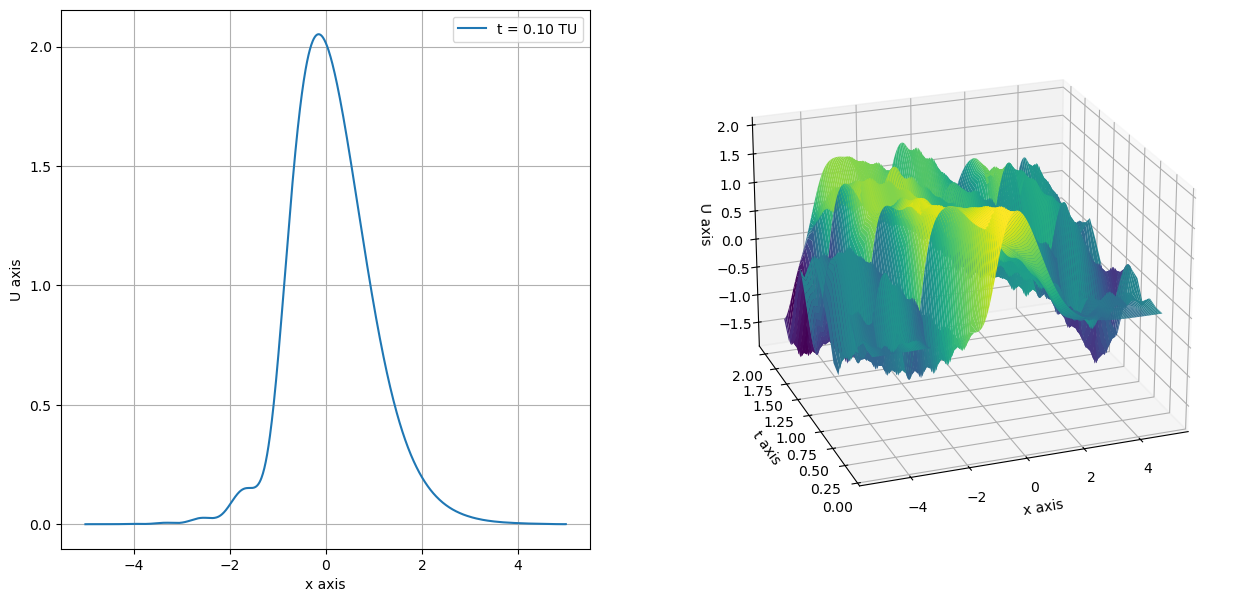

Plotting simulation results...
Index of time step closest to 0 TU: 0


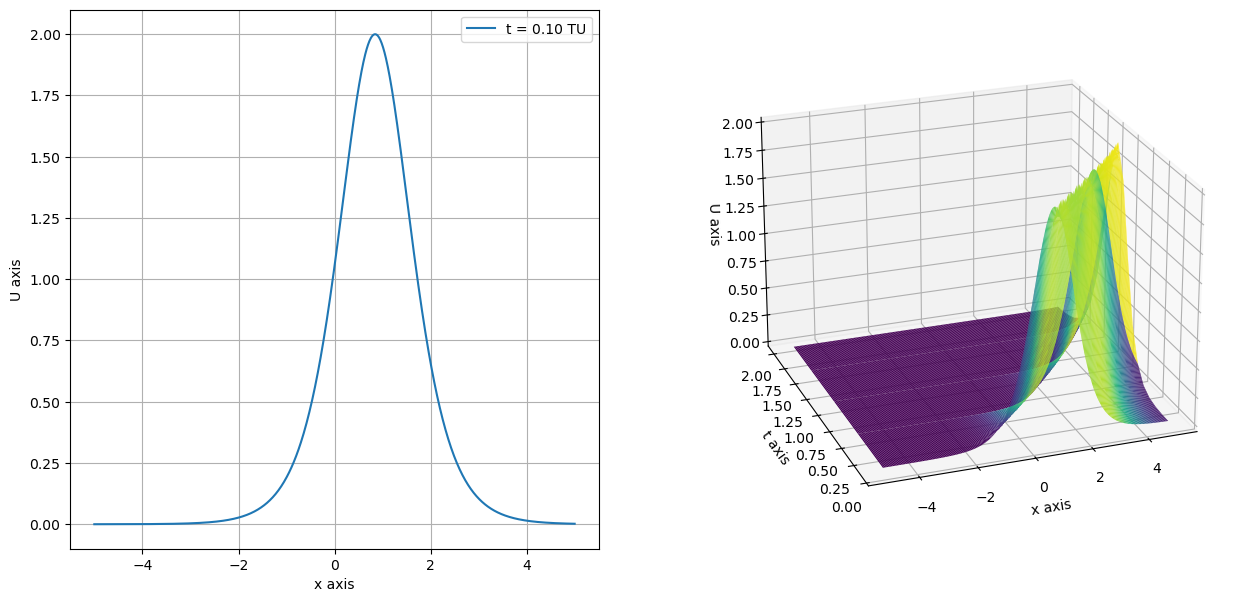

Index of time step closest to 0 TU: 0


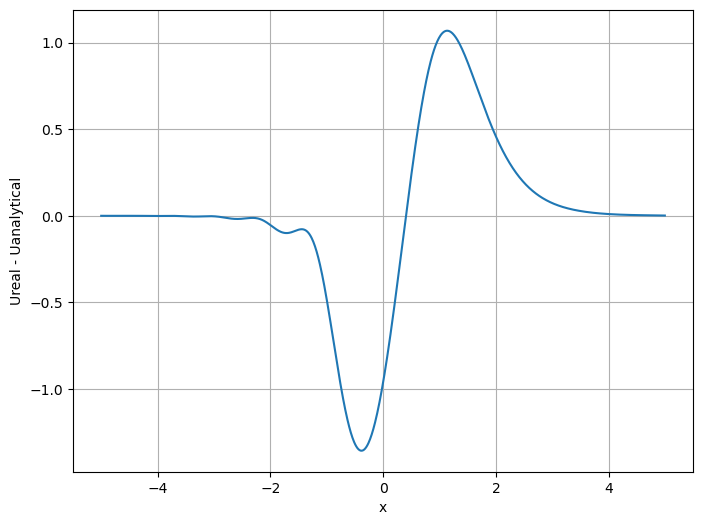

In [21]:
def eqn_55_exact( alpha, beta, delta, k, b, x, t):
    """ t = time"""
    wave_const = np.exp(b[2]*(t**2) + b[1]*t + b[0])
    return ( (12*k*beta) / alpha ) * ( (k**3)*(4*beta - delta) - (2*t*b[2] + b[1])*wave_const) * sech_sqrd(k * (x - delta * (k**2) * t) - wave_const)

def eqn_56_exact( beta, delta, k, b, x, t):
    """ t = time"""
    wave_const = np.exp(b[2] * (t ** 2) + b[1] * t + b[0])
    return 12 * beta * (k ** 2) * sech_sqrd(k * (x - delta * (k ** 2) * t) - wave_const)


alpha = -2.0
beta = 1/6
delta = 4.0
k = 1.0
b = [-1, 2, -1]

L = 5.0  # size of the domain in debye lengths
N = 1024  # number of discretised points in the domain (power of 2 for FFT speed)
dt = 1e-6  # TU
t_inital = 0.0 # TU
t_final =  2.0   # TU

time_stamp = 0

appened_eqn_55_exact = partial(eqn_55_exact, alpha, beta, delta, k, b) # forcing function
appened_eqn_56_exact = partial(eqn_56_exact, beta, delta, k, b) # wave solution

"""
fk_anal_sol, fk_anal_time_array, xa = run_simulation(L, N, t_inital, t_final, 1e-7, alpha, beta,
                                          mode="analytical",
                                          analytical_sol=appened_eqn_56_exact,
                                          forcing_fn=appened_eqn_55_exact,
                                          verbose=100000,
                                          solver = fw_solver
)
view_simulation_results(fk_anal_sol, fk_anal_time_array, xa, time_stamp)
"""

ck_anal_sol, ck_anal_time_array, xa = run_simulation(L, N, t_inital, t_final, 1e-3, alpha, beta,
                                          mode="analytical",
                                          analytical_sol=appened_eqn_56_exact,
                                          forcing_fn=appened_eqn_55_exact,
                                          verbose=100,
                                          solver = ck_solver
)
view_simulation_results(ck_anal_sol, ck_anal_time_array, xa, time_stamp)

eqn_56_sol = get_real_solutions(appened_eqn_56_exact, xa, anal_time_array)
view_simulation_results(eqn_56_sol, anal_time_array, xa, time_stamp)

i_anal = find_time_index(anal_time_array, time_stamp)

plt.figure(figsize=(8, 6))
plt.plot(xa, eqn_56_sol[i_anal] - anal_sol[i_anal], label="Difference between numerical and analytical solutions")
plt.xlabel("x")
plt.ylabel("Ureal - Uanalytical")
plt.grid()


### eqn 57 and eqn 58 from the NASA paper
$$
\begin{gathered}
f(x, t)=\frac{12 k \beta}{\alpha}\left(k^3(4 \beta-\delta)-\frac{b A}{1+A^2 t^2}-b_1\right) \operatorname{sech}^2\left(k\left(x-\delta k^2 t\right)-\left(b \arctan (A t)+b_1 t+b_0\right)\right) \\
U(x, t)=12 \beta k^2 \operatorname{sech}^2\left(k\left(x-4 k^2 t\right)-\left(b \arctan (A t)+b_1 t+b_0\right)\right)
\end{gathered}
$$

In [ ]:
def eqn_57_exact( alpha, beta, delta, k, A, b, x, t):
    """ t = time"""
    _wave_const = b[2]*np.arctan(A*t) + b[1]*t + b[0]
    return (12*k*beta / alpha) * ( (k**3) * (4*beta - delta) - ( b[2]*A / (1 + (A**2) * (t**2)) ) - b[1]) * sech_sqrd(k * (x - delta*(k**2)*t) - _wave_const)

def eqn_58_exact( beta, k, A, b, x, t):
    """ t = time"""
    _wave_const = b[2] * np.arctan(A*t) + b[1] * t + b[0]
    return 12 * beta * (k ** 2) * sech_sqrd(k * (x - 4 * (k ** 2) * t) - _wave_const)

k = 1.0
A = 3.0
delta = 4.0
b = [0.0, -3.0, -1]

alpha = 2.0
beta = 1/4

L = 5.0  # size of the domain in debye lengths
N = 1024  # number of discretised points in the domain (power of 2 for FFT speed)
dt = 1e-4  # TU
t_inital = -2.0  # TU
t_final =  2.0   # TU

time_stamp = 2

appened_eqn_57_exact = partial(eqn_57_exact, alpha, beta, delta, k, A, b) # forcing function
appened_eqn_58_exact = partial(eqn_58_exact, beta, k, A, b) # wave solution

# analytical
anal_sol, anal_time_array, xa= run_simulation(L, N, t_inital, t_final, dt, alpha, beta,
                                          mode="analytical",
                                          analytical_sol=appened_eqn_58_exact,
                                          forcing_fn=appened_eqn_57_exact,
                                          verbose=100
)
view_simulation_results(anal_sol, anal_time_array, xa, time_stamp)

eqn_58_sol = get_real_solutions(appened_eqn_58_exact, xa, anal_time_array)
view_simulation_results(eqn_58_sol, anal_time_array, xa, time_stamp)

i_anal = find_time_index(anal_time_array, time_stamp)

plt.figure(figsize=(8, 6))
plt.plot(xa, eqn_58_sol[i_anal] - anal_sol[i_anal], label="Difference between numerical and analytical solutions")
plt.xlabel("x")
plt.ylabel("Unumerical - Uanalytical")
plt.grid()

### Wu solution

In [ ]:
def wu_wave_exact(A, K, x, t):
    return A * (np.cosh(K * x) ** (-2))

def wu_forcing_exact( b1, K, x, t):
    return 2 * b1 * (np.cosh(K * x) ** (-2))

# Initial conditions
A = 0.5
b1 = -0.1250
K = 0.6124

# physical parameters
alpha = 1.0051 # Nonlinearity parameter ( 1.0051)
beta = 0.4925 # Dispersion parameter (0.4925)

# Simulation parameters
N = 1024  # number of discretised points in the domain (power of 2 for FFT speed)
L = 160.0  # size of the domain in debye lengths
dt = 1e-3  # TU
t_inital = 0.0  # TU
t_final =  60.0   # TU

time = 58.0 # TU


appended_wu_wave_exact = partial(wu_wave_exact, A, K)
appended_wu_forcing_exact = partial(wu_forcing_exact, b1, K)


wu_num_sol, wu_num_time_array, x = run_simulation(L, N, t_inital, t_final, dt, alpha, beta,
                                          mode="rest",
                                          forcing_fn=appended_wu_forcing_exact,
                                          verbose=100
)
view_simulation_results(wu_num_sol, wu_num_time_array, x, time, debris_pos=True)

wu_anal_sol, wu_anal_time_array, _ = run_simulation(L, N, t_inital, t_final, dt, alpha, beta,
                                          mode="analytical",
                                          analytical_sol=appended_wu_wave_exact,
                                          forcing_fn=appended_wu_forcing_exact,
                                          verbose=100
)
view_simulation_results(wu_anal_sol, wu_anal_time_array, x, time)


plt.figure(figsize=(8, 6))

for i_anal in range(len(wu_anal_time_array)):
    if abs(wu_anal_time_array[i_anal] - time) < 1e-2:
        print(i_anal)
        break
for i_num in range(len(wu_num_time_array)):
    if abs(wu_num_time_array[i_num] - time) < 1e-2:
        print(i_num)
        break
a
print(wu_num_time_array[i_num], wu_anal_time_array[i_anal])
plt.plot(x, wu_num_sol[i_num] - wu_anal_sol[i_anal], label="Difference between numerical and analytical solutions")
plt.xlabel("x")
plt.ylabel("Unumerical - Uanalytical")
plt.grid()
plt.title("Comparison of Numerical and Analytical Solutions at Final Time Step")